# BookMatch: EDA

Оценки, активность пользователей, популярность книг и теги.

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.data import load_data

books, ratings, tags, book_tags = load_data()
raw_ratings = pd.read_csv('data/archive/ratings.csv')
raw_book_tags = pd.read_csv('data/archive/book_tags.csv')
for name, frame in [('books', books), ('ratings', raw_ratings), ('tags', tags), ('book_tags', raw_book_tags)]:
    print(name, frame.shape)
    display(frame.head())


books (10000, 23)


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.78043902348e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.78043955493e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.78031601584e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.78006112008e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.78074327356e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


ratings (981756, 3)


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


tags (34252, 2)


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


book_tags (999912, 3)


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


## 1. Проверка данных

В исходных файлах `ratings.book_id` соответствует `books.id`, а `book_tags.goodreads_book_id` — `books.book_id`. Загрузчик переименовывает ID каталога в `book_id` и `goodreads_book_id`

Полные дубли удаляются. Пары с разными оценками исключаются: дат для выбора последней оценки нет. Для тегов исключаются конфликтующие и отрицательные веса

In [2]:
distinct_ratings = raw_ratings.drop_duplicates()
conflicts = distinct_ratings.duplicated(['user_id', 'book_id'], keep=False)
print('Полных дублей оценок:', len(raw_ratings) - len(distinct_ratings))
print('Конфликтных пар:', distinct_ratings.loc[conflicts, ['user_id', 'book_id']].drop_duplicates().shape[0])
print('Оценок после очистки:', len(ratings))
print('Связей книга–тег после очистки:', len(book_tags))
missing = books.isna().sum()
missing[missing > 0]


Полных дублей оценок: 1644
Конфликтных пар: 633
Оценок после очистки: 978845
Связей книга–тег после очистки: 999896


isbn                          700
isbn13                        585
original_publication_year      21
original_title                585
language_code                1084
dtype: int64

## 2. Распределение оценок

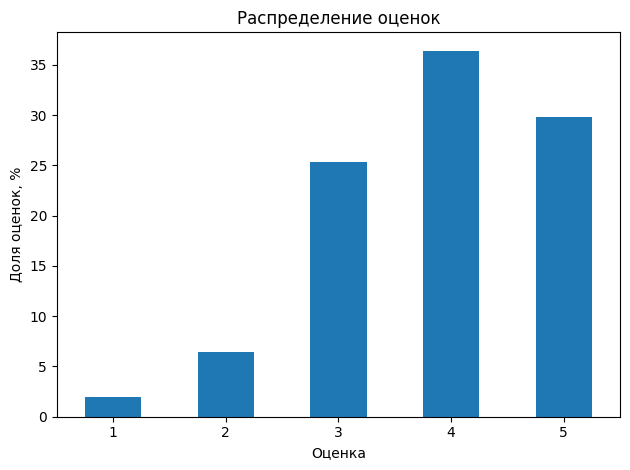

Средняя оценка: 3.856
Доля оценок 4–5: 0.662


In [3]:
rating_counts = ratings.rating.value_counts().sort_index()
(rating_counts / len(ratings) * 100).plot.bar(rot=0)
plt.xlabel('Оценка')
plt.ylabel('Доля оценок, %')
plt.title('Распределение оценок')
plt.tight_layout()
plt.show()
print('Средняя оценка:', round(ratings.rating.mean(), 3))
print('Доля оценок 4–5:', round((ratings.rating >= 4).mean(), 3))


Оценки смещены в сторону высоких значений: около 66% составляют 4–5.

## 3. Активность пользователей

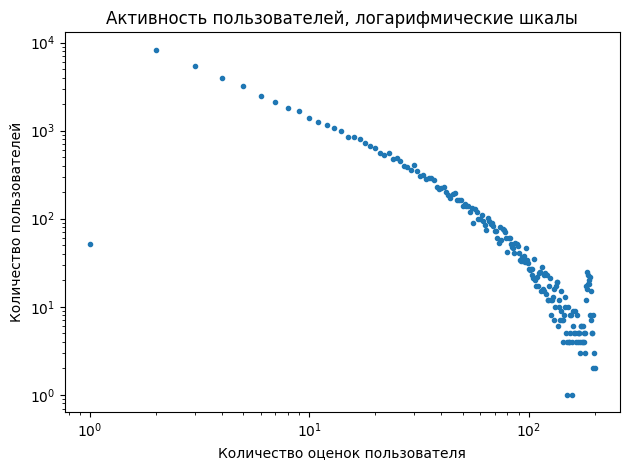

count    53417.000000
mean        18.324597
std         26.213750
min          1.000000
25%          3.000000
50%          8.000000
75%         22.000000
max        200.000000
dtype: float64

Пользователей с 1–2 оценками: 8363
Самые активные пользователи:


user_id
12874    200
30944    200
12381    199
28158    199
52036    199
6630     197
45554    197
7563     196
9668     196
9806     196
dtype: int64

In [4]:
user_counts = ratings.groupby('user_id').size()
user_counts.value_counts().sort_index().plot(marker='.', linestyle='none')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Количество оценок пользователя')
plt.ylabel('Количество пользователей')
plt.title('Активность пользователей, логарифмические шкалы')
plt.tight_layout()
plt.show()
display(user_counts.describe())
print('Пользователей с 1–2 оценками:', (user_counts <= 2).sum())
print('Самые активные пользователи:')
user_counts.nlargest(10)


У пользователей с короткой историей мало данных для персональных рекомендаций. При разбиении истории из 1–2 оценок остаются в train

## 4. Популярность книг

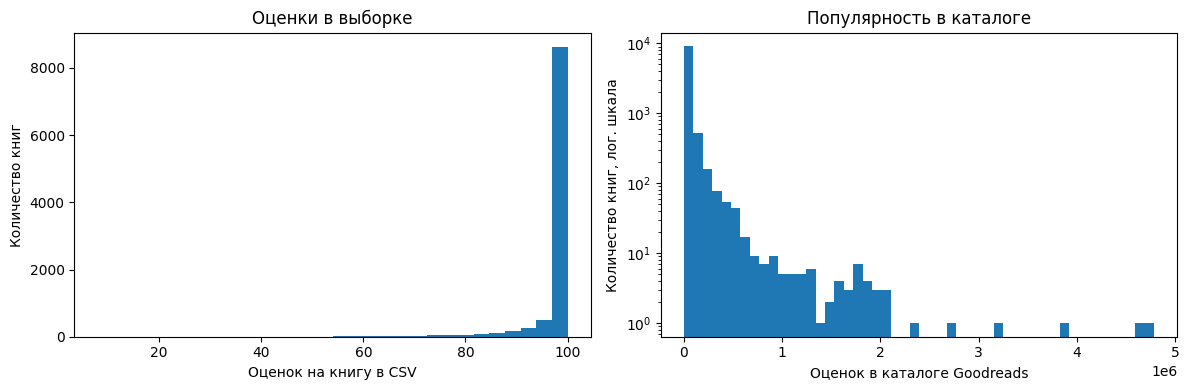

Максимум оценок на книгу в CSV: 100
Доля книг с этим числом: 0.746


,book_id,title,ratings_count
0,1,"The Hunger Games (The Hunger Games, #1)",4780653
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,4602479
2,3,"Twilight (Twilight, #1)",3866839
3,4,To Kill a Mockingbird,3198671
4,5,The Great Gatsby,2683664
5,6,The Fault in Our Stars,2346404
6,7,The Hobbit,2071616
7,8,The Catcher in the Rye,2044241
9,10,Pride and Prejudice,2035490
8,9,"Angels & Demons (Robert Langdon, #1)",2001311


In [5]:
book_counts = ratings.groupby('book_id').size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(book_counts, bins=30)
axes[0].set(xlabel='Оценок на книгу в CSV', ylabel='Количество книг', title='Оценки в выборке')
axes[1].hist(books.ratings_count, bins=50)
axes[1].set(yscale='log', xlabel='Оценок в каталоге Goodreads', ylabel='Количество книг, лог. шкала', title='Популярность в каталоге')
plt.tight_layout()
plt.show()
raw_counts = raw_ratings.groupby('book_id').size()
print('Максимум оценок на книгу в CSV:', raw_counts.max())
print('Доля книг с этим числом:', round((raw_counts == raw_counts.max()).mean(), 3))
books.nlargest(10, 'ratings_count')[['book_id', 'title', 'ratings_count']]


В CSV большинство книг имеет около 100 оценок, что указывает на ограничение выгрузки. Каталожный `ratings_count` показывает длинный хвост: у немногих книг очень много оценок. Больше взаимодействий даёт популярным книгам больше данных для обучения. Редкие книги могут реже попадать в рекомендации. Ограничение выгрузки искажает эту картину. Для обучения используются только оценки из train, а не агрегаты каталога

## 5. Теги

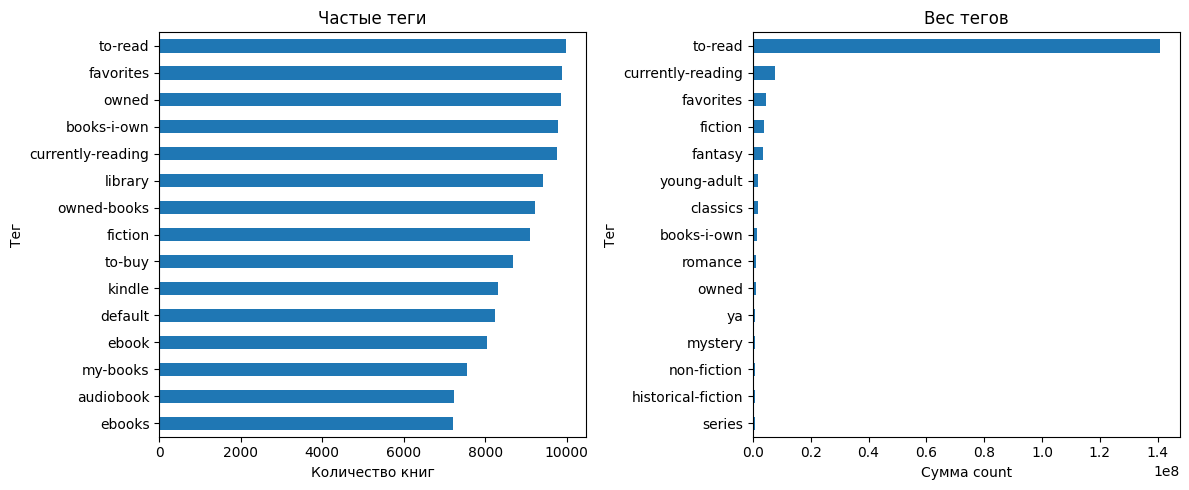

In [6]:
book_tags_named = book_tags.merge(tags, on='tag_id', validate='many_to_one')
tag_weights = book_tags_named.groupby('tag_name')['count'].sum()
tag_frequency = book_tags_named.groupby('tag_name').goodreads_book_id.nunique()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
tag_frequency.nlargest(15).sort_values().plot.barh(ax=axes[0])
axes[0].set(title='Частые теги', xlabel='Количество книг', ylabel='Тег')
tag_weights.nlargest(15).sort_values().plot.barh(ax=axes[1])
axes[1].set(title='Вес тегов', xlabel='Сумма count', ylabel='Тег')
plt.tight_layout()
plt.show()


Среди тегов есть жанры и служебные полки, например `to-read`. В контентной модели служебные полки исключаются.

## 6. Выводы

In [7]:
n_users = ratings.user_id.nunique()
n_books = books.book_id.nunique()
density = len(ratings) / (n_users * n_books)
print('Пользователей:', n_users)
print('Книг:', n_books)
print('Разреженность, %:', round((1 - density) * 100, 3))


Пользователей: 53417
Книг: 10000
Разреженность, %: 99.817


- Матрица разрежена примерно на 99,82%. Нужна разреженная форма хранения
- Высокие оценки преобладают. Отсутствие оценки не означает отрицательный отклик
- Короткие истории затрудняют персонализацию
- Популярность книг в выборке и в каталоге различается из-за ограничения выгрузки
- Дат событий нет, поэтому используется случайное разбиение внутри пользователя